In [33]:
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
print(sys.executable)
print(pd.__version__)

C:\ProgramData\anaconda3\envs\pew-analysis\python.exe
3.0.6


## 1. Load the data and dictionary

Each row represents a respondent. Each columns store answers, demographic information, and survey metadata.

In [7]:
data_folder = Path.cwd()

global_file = (
    data_folder
    / "Pew-Research-Center-Global-Attitudes-Spring-2025-Public"
    / "Pew Research Center Global Attitudes Spring 2025 Dataset CSV.csv"
)

global_data = pd.read_csv(global_file, low_memory=False)

print("Rows:", global_data.shape[0])
print("Columns:", global_data.shape[1])
print(f"Countries: {global_data.country.nunique()}")

global_data.head()

Rows: 28333
Columns: 483
Countries: 24


,survey,country,weight,id,econ_sit,satisfied_democracy,polsys_satisfied,fav_us,fav_china,fav_eu,...,region_skorea,region_spain,region_sweden,region_turkey,region_uk,urbanicity,qdate_s,qdate_e,intdate_aus,phone_sample
0,1202501,2,0.592005,8001432,2,2,,4,3,2,...,,,,,,,3/23/2025,3/23/2025,,1
1,1202501,2,0.446814,8003472,4,3,,4,4,2,...,,,,,,,3/11/2025,3/11/2025,,1
2,1202501,2,1.120110,8006468,2,1,,3,8,2,...,,,,,,,4/1/2025,4/1/2025,,1
3,1202501,2,0.695317,8006970,2,1,,4,8,1,...,,,,,,,3/10/2025,3/10/2025,,1
4,1202501,2,0.369352,8008601,2,2,,4,3,1,...,,,,,,,3/23/2025,3/23/2025,,1


## 2. Translate response codes into labels

Pew stores survey responses as numbers. The data dictionary explains what each number means. For example, in the `country` column, code **2** represents **Canada**.

This code reads the dictionary’s **Values** sheet and names its columns `variable`, `code`, and `label`. In the Excel sheet, each variable’s name appears only beside its first response code. The `.ffill()` step fills that name into the rows below so every code is linked to its question.

The code then defines a reusable function called `decoded()`. Given a column name, this function finds its response codes in the dictionary and translates them into labels.

For example, `decoded("country")` returns country names, while `decoded("ai_heard")` returns answers such as **A lot**, **A little**, and **Nothing at all**.

The original data stays unchanged. Blank values or codes without a matching dictionary entry appear as missing values in the decoded result.

In [14]:
# Read Pew's response codes and labels
dictionary_file = (
    data_folder
    / "Pew-Research-Center-Global-Attitudes-Spring-2025-Public"
    / "Pew Research Center Global Attitudes Spring 2025 Data Dictionary.xlsx"
)

values = pd.read_excel(
    dictionary_file,
    sheet_name="Values",
    header=1
)

values.columns = ["variable", "code", "label"]
values["variable"] = values["variable"].ffill()


# Define a function to translate codes into labels
def decoded(column):
    question_codes = values.loc[
        values["variable"] == column,
        ["code", "label"]
    ].dropna(subset=["code"])

    mapping = dict(zip(question_codes["code"], question_codes["label"]))

    return pd.to_numeric(
        global_data[column], errors="coerce"
    ).map(mapping)

# 3. Sample Sizes and Country Count
This count shows how many interviews are there for each country

In [13]:
country_counts = (
    decoded("country")
    .value_counts()
    .rename_axis("Country")
    .reset_index(name="Respondents")
)

display(country_counts.sort_values("Country").reset_index(drop=True))

,Country,Respondents
0,Argentina,1001
1,Australia,1829
2,Brazil,1053
3,Canada,1024
4,France,1006
5,Germany,1006
6,Greece,1010
7,Hungary,1020
8,India,3545
9,Indonesia,1022


## 4. Explore the survey topics

This dataset covers several topics, with multiple questions under each topic.

I read the variable names and question descriptions to understand what the survey covers. Some columns contain survey information or demographic details rather than opinion questions.

In [27]:
# # Show full question descriptions
# pd.set_option("display.max_colwidth", None)

# # Print each variable and its description
# for index, row in catalogue.iterrows():
#     print(row["Variable"])
#     print(row["Label"])
#     print()

### 6. Explore the survey questions

This code reads the question descriptions from the data dictionary. It keeps the variable name, question wording, and measurement type for columns in our dataset.

I start by searching for **artificial intelligence**.

In [19]:
# Read the Variables sheet from the data dictionary
variables = pd.read_excel(
    dictionary_file,
    sheet_name="Variables",
    header=1
)

# Select the columns we want to see
catalogue = variables[
    ["Variable", "Label", "Measurement Level"]
].copy()

# Keep only variables that are in our dataset
in_dataset = catalogue["Variable"].isin(global_data.columns)
catalogue = catalogue[in_dataset]

# Choose a topic to search for
search_word = "artificial intelligence"

# Find question descriptions containing that topic
matching_questions = catalogue["Label"].str.contains(
    search_word,
    case=False,
    regex=False,
    na=False
)

# Show the matching questions
results = catalogue[matching_questions]
# Show the full question wording in tables
pd.set_option("display.max_colwidth", None)
print("Number of matching questions:", len(results))
display(results)

Number of matching questions: 6


,Variable,Label,Measurement Level
201,ai_heard,"Q30. Artificial intelligence, also known as AI, is designed to learn tasks that humans typically do, for instance recognizing speech or pictures. Have you heard or read a lot, a little, or nothing at all about artificial intelligence?",Nominal
202,ai_cncexc,"Q31. Overall, how would you say the increased use of artificial intelligence in daily life makes you feel?",Nominal
203,aireg_us,Q32a. (SHORTENED) How much trust do you have in each of the following countries and organizations to regulate the use of artificial intelligence effectively? a. The United States,Nominal
204,aireg_china,Q32b. (SHORTENED) How much trust do you have in each of the following countries and organizations to regulate the use of artificial intelligence effectively? b. China,Nominal
205,aireg_eu,Q32c. (SHORTENED) How much trust do you have in each of the following countries and organizations to regulate the use of artificial intelligence effectively? c. The European Union,Nominal
206,aireg_country,Q32d. (SHORTENED) How much trust do you have in each of the following countries and organizations to regulate the use of artificial intelligence effectively? d. (survey country),Nominal


## 5. Group the survey questions by topic

I tried to organize the variables into broad groups so I can explore one topic at a time.

These are working groups based on the question descriptions. 
The counts show the number of variables in each group. A variable may be a question item, a country-specific version, or a background field.

In [31]:
# Make a separate copy of the question catalogue
grouped_questions = catalogue.copy()

# Read the question number from labels such as Q30 or Q32a
question_numbers = grouped_questions["Label"].str.extract(r"^Q(\d+)")[0]
grouped_questions["Question number"] = pd.to_numeric(question_numbers)

# Store a group name for each variable
groups = []

for number in grouped_questions["Question number"]:

    if number in [30, 31, 32]:
        group = "Artificial intelligence"

    elif number == 105:
        group = "Internet use"

    elif number in [2, 4, 5, 10, 11, 20, 21, 22, 23, 47, 100, 101]:
        group = "Politics and government"

    elif number in [1, 12, 14]:
        group = "Economy"

    elif number in [3, 6, 7, 8, 9, 24, 25, 26, 27,
                    33, 34, 35, 36, 37, 44, 45, 46, 53]:
        group = "International views"

    elif number in [16, 17, 18, 90, 91, 92, 93, 94, 95]:
        group = "Religion and moral values"

    elif number in [19, 104]:
        group = "Citizenship and social trust"

    elif number in [38, 39, 40, 41, 42, 43]:
        group = "Climate change"

    elif number in [48, 49, 50, 51]:
        group = "Discrimination and inequality"

    elif number in [77, 78, 79, 80, 81, 82, 83, 84, 85]:
        group = "Israel and Palestine"

    elif number in [88, 89, 96, 97, 98, 99]:
        group = "Respondent background"

    else:
        group = "Needs review"

    groups.append(group)

# Add the group names to the catalogue
grouped_questions["Group"] = groups

# Group location fields with respondent background
location_fields = grouped_questions["Variable"].str.startswith("region_")
grouped_questions.loc[location_fields, "Group"] = "Respondent background"

grouped_questions.loc[
    grouped_questions["Variable"] == "urbanicity",
    "Group"
] = "Respondent background"

# Identify survey information fields
survey_fields = [
    "survey", "country", "weight", "id",
    "home_phone", "working_cell",
    "qdate_s", "qdate_e", "intdate_aus", "phone_sample"
]

grouped_questions.loc[
    grouped_questions["Variable"].isin(survey_fields),
    "Group"
] = "Survey information"

# Count the variables in each group
group_counts = grouped_questions["Group"].value_counts()

display(group_counts.to_frame("Number of variables"))

,Number of variables
Group,
Politics and government,174
Respondent background,134
International views,66
Discrimination and inequality,29
Israel and Palestine,23
Religion and moral values,20
Citizenship and social trust,11
Survey information,10
Artificial intelligence,6


## 7. Decoding the six AI questions

These six questions ask about:

- **Awareness of AI**
- **Concern or excitement about its growing use**
- **Trust in different countries and institutions to regulate it**

The answers are stored as numeric codes. I use the **Values** sheet in the data dictionary to find what each code means.

The code below creates a separate table with the answers written as labels.

## Awareness of AI

**Question 30** asks how much respondents have heard or read about AI.
- **Artificial intelligence, also known as AI, is designed to learn tasks that humans typically do, for instance recognizing speech or pictures. Have you heard or read a lot, a little, or nothing at all about artificial intelligence?**

I translate the response codes into labels and show each respondent’s country alongside their answer and atleast one response from each country.

In [38]:
# Create a table for AI awareness
awareness = pd.DataFrame()

awareness["Country"] = decoded("country")
awareness["AI awareness"] = decoded("ai_heard")

display(awareness.head(10))
display(awareness.groupby("Country").head(1))

,Country,AI awareness
0,Canada,A little
1,Canada,A little
2,Canada,A little
3,Canada,A little
4,Canada,A lot
5,Canada,A little
6,Canada,A little
7,Canada,A little
8,Canada,A little
9,Canada,A lot


,Country,AI awareness
0,Canada,A little
1024,France,A lot
2030,Germany,A little
3036,Greece,A lot
4046,Hungary,A lot
5066,Italy,A lot
6073,Netherlands,A little
7073,Poland,A lot
8075,Spain,A little
9076,Sweden,Nothing at all


## Concern or excitement about AI

**Question 31** asks how respondents feel about the increasing use of AI in daily life.
- **Overall, how would you say the increased use of artificial intelligence in daily life makes you feel?**

I translate the response codes into labels and show the first 10 answers.

In [22]:
# Create a table for feelings about AI
feelings = pd.DataFrame()

feelings["Country"] = decoded("country")
feelings["Concern or excitement"] = decoded("ai_cncexc")

display(feelings.head(10))

,Country,Concern or excitement
0,Canada,More concerned than excited
1,Canada,Equally concerned and excited
2,Canada,More concerned than excited
3,Canada,More concerned than excited
4,Canada,Equally concerned and excited
5,Canada,More concerned than excited
6,Canada,More concerned than excited
7,Canada,More concerned than excited
8,Canada,More concerned than excited
9,Canada,Equally concerned and excited


## Trust in AI regulation

**Question 32** asks how much respondents trust their own country, the EU, the U.S., and China to regulate AI effectively.
- **How much trust do you have in each of the following countries and organizations to regulate the use of artificial intelligence effectively?**

Each table shows individual respondents answers

In [23]:
# Create a table for trust in AI regulation
regulation = pd.DataFrame()

regulation["Respondent's country"] = decoded("country")
regulation["Trust in own country"] = decoded("aireg_country")
regulation["Trust in EU"] = decoded("aireg_eu")
regulation["Trust in U.S."] = decoded("aireg_us")
regulation["Trust in China"] = decoded("aireg_china")

display(regulation.head(10))

,Respondent's country,Trust in own country,Trust in EU,Trust in U.S.,Trust in China
0,Canada,Some trust,Some trust,Some trust,Not sure
1,Canada,Some trust,Some trust,No trust at all,No trust at all
2,Canada,Some trust,Not sure,No trust at all,No trust at all
3,Canada,Some trust,A lot of trust,No trust at all,No trust at all
4,Canada,Some trust,Some trust,Not too much trust,Not too much trust
5,Canada,A lot of trust,Some trust,Some trust,No trust at all
6,Canada,Some trust,Some trust,Not too much trust,Not too much trust
7,Canada,Some trust,Not too much trust,Not too much trust,Not too much trust
8,Canada,A lot of trust,Some trust,No trust at all,Not sure
9,Canada,Some trust,Some trust,Some trust,Not too much trust


## View all six answers together

This table shows each respondent’s country and their responses of all six AI questions. I display the first 10 respondents responses.

In [25]:
# Put all six AI answers in one table
ai_answers = pd.DataFrame()

ai_answers["country"] = decoded("country")
ai_answers["ai_heard"] = decoded("ai_heard")
ai_answers["ai_cncexc"] = decoded("ai_cncexc")
ai_answers["aireg_country"] = decoded("aireg_country")
ai_answers["aireg_eu"] = decoded("aireg_eu")
ai_answers["aireg_us"] = decoded("aireg_us")
ai_answers["aireg_china"] = decoded("aireg_china")

display(ai_answers.head(10))

,country,ai_heard,ai_cncexc,aireg_country,aireg_eu,aireg_us,aireg_china
0,Canada,A little,More concerned than excited,Some trust,Some trust,Some trust,Not sure
1,Canada,A little,Equally concerned and excited,Some trust,Some trust,No trust at all,No trust at all
2,Canada,A little,More concerned than excited,Some trust,Not sure,No trust at all,No trust at all
3,Canada,A little,More concerned than excited,Some trust,A lot of trust,No trust at all,No trust at all
4,Canada,A lot,Equally concerned and excited,Some trust,Some trust,Not too much trust,Not too much trust
5,Canada,A little,More concerned than excited,A lot of trust,Some trust,Some trust,No trust at all
6,Canada,A little,More concerned than excited,Some trust,Some trust,Not too much trust,Not too much trust
7,Canada,A little,More concerned than excited,Some trust,Not too much trust,Not too much trust,Not too much trust
8,Canada,A little,More concerned than excited,A lot of trust,Some trust,No trust at all,Not sure
9,Canada,A lot,Equally concerned and excited,Some trust,Some trust,Some trust,Not too much trust


## 8. Trust in the EU and U.S. together

This chart shows how many Canadian respondents trust both the EU and the U.S., only one of them, or neither to regulate AI.

The bars show sample counts without survey weights. Respondents who answered “Not sure,” refused, or had a missing answer on either question are excluded.

,Respondents
Trust both,272
Trust EU only,352
Trust U.S. only,53
Trust neither,159


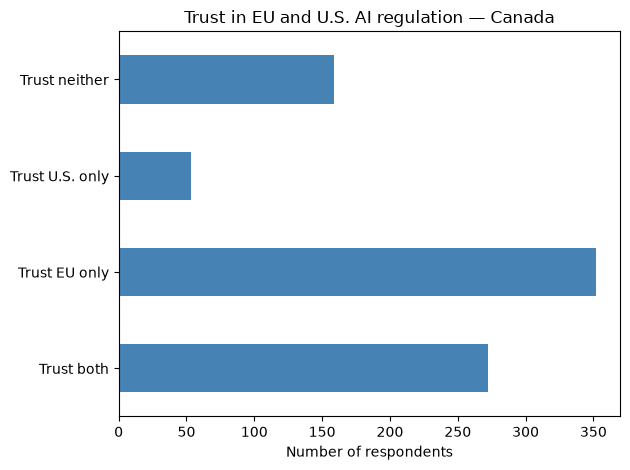

In [36]:
# Select Canadian respondents
canada = global_data[decoded("country") == "Canada"]

# Keep trust or distrust answers for both questions
valid_answers = (
    canada["aireg_eu"].isin([1, 2, 3, 4])
    & canada["aireg_us"].isin([1, 2, 3, 4])
)

answers = canada[valid_answers]

# Codes 1 and 2 mean trust
trust_eu = answers["aireg_eu"].isin([1, 2])
trust_us = answers["aireg_us"].isin([1, 2])

# Count the four combinations
counts = pd.Series({
    "Trust both": (trust_eu & trust_us).sum(),
    "Trust EU only": (trust_eu & ~trust_us).sum(),
    "Trust U.S. only": (~trust_eu & trust_us).sum(),
    "Trust neither": (~trust_eu & ~trust_us).sum()
})

# Show the counts and draw a chart
display(counts.to_frame("Respondents"))

counts.plot.barh(color="steelblue")
plt.title("Trust in EU and U.S. AI regulation — Canada")
plt.xlabel("Number of respondents")
plt.tight_layout()
plt.show()